<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Project 1: Data Analysis of Singapore Rainfall

### Contents:
- [Background](#Background)
- [Problem Statement](#Problem-Statement)
- [Data Import & Cleaning](#Data-Import-and-Cleaning)
- [Exploratory Data Analysis](#Exploratory-Data-Analysis)
- [Data Visualization](#Visualize-the-Data)
- [Conclusions and Recommendations](#Conclusions-and-Recommendations)

## Background

According to the [Meteorological Services Singapore](http://www.weather.gov.sg/climate-climate-of-singapore/#:~:text=Singapore%20is%20situated%20near%20the,month%2Dto%2Dmonth%20variation.), Singapore has typical tropical climate with adundant rainfall, high and uniform temperatures and high humidity all year round, since it's situated near the equator. There are many factors that help us understand the climate of a country and in this project we are going to look into a few, especially rainfall.

Singapore’s climate is characterised by two main monsoon seasons separated by inter-monsoonal periods.  The **Northeast Monsoon** occurs from December to early March, and the **Southwest Monsoon** from June to September.

The major weather systems affecting Singapore that can lead to heavy rainfall are:

-Monsoon surges, or strong wind episodes in the Northeast Monsoon flow bringing about major rainfall events;

-Sumatra squalls, an organised line of thunderstorms travelling eastward across Singapore, having developed over the island of Sumatra or Straits of Malacca west of us;

-Afternoon and evening thunderstorms caused by strong surface heating and by the sea breeze circulation that develops in the afternoon.

Singapore’s climate station has been located at several different sites in the past 140 years. The station had been decommissioned at various points in the past due to changes to local land use in the site’s vicinity, and had to be relocated. Since 1984, the climate station has been located at **Changi**.

There are other metrics of climate such as temperature, humidity, sun shine duration, wind speed, cloud cover etc. All datasets used in the project comes from [data.gov.sg](data.gov.sg), as recorded at the Changi climate station, as well as [singstat.gov.sg](singstat.gov.sg).

## Problem Statement

Rain is plentiful in Singapore and it rains an [average of 167 days per year](http://www.weather.gov.sg/climate-climate-of-singapore/). Unlike countries in the temperate regions, temperatures in Singapore are high and relatively uniform with little variance from month to month and from day to day. Being a peninsular island surrounded by seas, the humidity level in Singapore is also typically high, which will influence how our bodies sense and experience warmth. These weather conditions are expected to have an impact on how people in Singapore choose their activities for the day as well as how they would use electricity based on the activities chosen. This project aims to provide a data-driven analysis to understand if there is a correlation among the aforementioned factors. If a correlation between weather and electricity consumption can be identified, relevant national agencies working on climate change issues can use these findings to plan more effective carbon emission reduction strategy.

### Datasets

The datasets that will be used in this analysis are:

* [`weather.csv`](data/weather.csv) where part of the data has been provided in the project data folder and the remaining downloaded from [singstat.gov.sg](https://tablebuilder.singstat.gov.sg/table/TS/M890081): 
    - Monthly total rain recorded in mm(millimeters) from 1982 to 2022
    - Monthly number of rain days from 1982 to 2022. A day is considered to have “rained” if the total rainfall for that day is 0.2mm or more.
    - Monthly mean daily maximum air temperature from 1982 to 2022
    - Monthly mean daily minimum air temperature from 1982 to 2022
    - Monthly mean daily bright sunshine hours from 1982 to 2022
    - Monthly mean 24 hours humidity from 1982 to 2022


* [`electricity.csv`](data/electricity.csv) which came from [ema.gov.sg](https://www.ema.gov.sg/statistic.aspx?sta_sid=20140729cKpjlPbDaOxa): 
    - Average Monthly Household Electricity Consumption from 2005 to 1H 2022

### Outside Research

According to Singapore's [National Climate Change Secretariat (NCCS)](https://www.nccs.gov.sg/singapores-climate-action/impact-of-climate-change-in-singapore/), the country has experienced rising temperatures and more frequent extreme weather events in recent years. From 1980 to 2020, the annual mean temperature has increased from 26.9°C to 28.0°C. Rainfall has also become more intense with annual rainfall total increased at an average rate of 67 mm per decade from 1980 to 2019. 

These climate change patterns are expected to have significant impacts on household electricity consumption in Singapore. For instance, as temperatures and/or humidity level rise, households are likely to use air conditioning more frequently, leading to higher carbon emissions. According to a [commentary report by Channel News Asia](https://www.channelnewsasia.com/commentary/air-con-unit-electricity-energy-carbon-emissions-climate-change-1339326), household and building use of air-conditioning made up 19% of Singapore’s carbon emissions, making it the second highest source of emissions after the industrial sector, which accounted for 60 per cent of emissions.

Findings by Singapore's [National Environment Agency (NEA)](https://www.nea.gov.sg/media/news/news/index/four-in-five-households-motivated-to-save-energy-if-they-can-save-money-nea-study#:~:text=Household%20Energy%20Consumption%20in%20Singapore&text=5%20A%20survey%20conducted%20by,lamps%2C%20fans%20and%20television%20sets.) showed that Singapore’s household electricity consumption has been steadily rising over the years. In 2017, households consumed a total of about 7,295 GWh – an increase of 17 per cent compared to ten years ago. Additionally, it was found that air-conditioning made up the biggest portion of an average Singaporean household’s electricity consumption at 24%, followed by refrigerators (17%) and water heaters (11%). Other energy guzzlers included lamps, fans and television sets. 

An increase in carbon footprint will have immense implications for the world we live in. By adding more carbon dioxide to the atmosphere, the natural greenhouse effect is amplified, which in turn causes global temperature to rise. According to a report by United States' [National Oceanic and Atmospheric Administration (NOAA)](https://www.climate.gov/news-features/understanding-climate/climate-change-atmospheric-carbon-dioxide#:~:text=Without%20carbon%20dioxide%2C%20Earth's%20natural,causing%20global%20temperature%20to%20rise.), in 2021 carbon dioxide alone was responsible for about two-thirds of the total heating influence of all human-produced greenhouse gases.

## Data Import and Cleaning

### Libraries to be used:

In [5]:
# Imports:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Data Import & Cleaning

In [6]:
# Import weather data
weather = pd.read_csv('data/weather.csv')
print(weather.shape)
weather.head()

(494, 7)


,date,total_rainfall,number_of_rainy_days,air_temperature_means_daily_max,air_temperature_means_daily_min,bright_sunshine_daily_mean_hour,24_hours_mean_relative_humidity_percent
0,1982-01,85.8,10,29.8,23.3,5.6,83.7
1,1982-02,97.4,5,32.3,23.9,7.6,82.1
2,1982-03,90.7,11,31.7,24.3,5.1,85.4
3,1982-04,227.5,14,31.4,24.3,4.7,88.1
4,1982-05,166.4,10,31.7,25.2,5.8,85.6


In [7]:
# Import electricity consumption data
electricity = pd.read_csv('data/electricity.csv')
print(electricity.shape)
electricity.head()

(210, 7)


,date,overall,central_region,east_region,northeast_region,north_region,west_region
0,2005-01,418.1,485.4,435.0,386.7,366.3,365.6
1,2005-02,408.3,459.0,429.5,382.4,357.5,368.7
2,2005-03,446.9,500.2,467.2,422.8,403.5,397.5
3,2005-04,496.2,566.4,538.3,463.9,422.5,431.1
4,2005-05,496.8,573.3,510.1,468.8,428.9,437.6


In [8]:
# Check for missing values
print(weather.isnull().sum())

date                                       0
total_rainfall                             0
number_of_rainy_days                       0
air_temperature_means_daily_max            0
air_temperature_means_daily_min            0
bright_sunshine_daily_mean_hour            0
24_hours_mean_relative_humidity_percent    0
dtype: int64


In [9]:
print(electricity.isnull().sum())

date                0
overall             0
central_region      0
east_region         0
northeast_region    0
north_region        0
west_region         0
dtype: int64


In [10]:
# Check for datatypes
print(weather.dtypes)

date                                        object
total_rainfall                             float64
number_of_rainy_days                         int64
air_temperature_means_daily_max            float64
air_temperature_means_daily_min            float64
bright_sunshine_daily_mean_hour            float64
24_hours_mean_relative_humidity_percent    float64
dtype: object


In [11]:
print(electricity.dtypes)

date                 object
overall             float64
central_region      float64
east_region         float64
northeast_region    float64
north_region        float64
west_region         float64
dtype: object


In [12]:
# Convert date column to datetime
weather['date'] = pd.to_datetime(weather['date'])
weather.head()

,date,total_rainfall,number_of_rainy_days,air_temperature_means_daily_max,air_temperature_means_daily_min,bright_sunshine_daily_mean_hour,24_hours_mean_relative_humidity_percent
0,1982-01-01,85.8,10,29.8,23.3,5.6,83.7
1,1982-02-01,97.4,5,32.3,23.9,7.6,82.1
2,1982-03-01,90.7,11,31.7,24.3,5.1,85.4
3,1982-04-01,227.5,14,31.4,24.3,4.7,88.1
4,1982-05-01,166.4,10,31.7,25.2,5.8,85.6


In [13]:
electricity['date'] = pd.to_datetime(electricity['date'])
electricity.head()

,date,overall,central_region,east_region,northeast_region,north_region,west_region
0,2005-01-01,418.1,485.4,435.0,386.7,366.3,365.6
1,2005-02-01,408.3,459.0,429.5,382.4,357.5,368.7
2,2005-03-01,446.9,500.2,467.2,422.8,403.5,397.5
3,2005-04-01,496.2,566.4,538.3,463.9,422.5,431.1
4,2005-05-01,496.8,573.3,510.1,468.8,428.9,437.6


In [14]:
# Check for duplicated rows
print(weather.duplicated().sum())
electricity.duplicated().sum()

0


0

In [15]:
# Check for - unique values
print(weather['date'].nunique())
electricity['date'].nunique()

494


210

In [16]:
# Create a new column for year and get the data from the date column
weather['year'] = weather['date'].dt.year

electricity['year'] = electricity['date'].dt.year

# move the 'year' column to the first position
cols = weather.columns.tolist()
cols.insert(0, cols.pop(cols.index('year')))
weather = weather[cols]

cols = electricity.columns.tolist()
cols.insert(0, cols.pop(cols.index('year')))
electricity = electricity[cols]

print(weather.head())
electricity.head()

   year       date  total_rainfall  number_of_rainy_days  \
0  1982 1982-01-01            85.8                    10   
1  1982 1982-02-01            97.4                     5   
2  1982 1982-03-01            90.7                    11   
3  1982 1982-04-01           227.5                    14   
4  1982 1982-05-01           166.4                    10   

   air_temperature_means_daily_max  air_temperature_means_daily_min  \
0                             29.8                             23.3   
1                             32.3                             23.9   
2                             31.7                             24.3   
3                             31.4                             24.3   
4                             31.7                             25.2   

   bright_sunshine_daily_mean_hour  24_hours_mean_relative_humidity_percent  
0                              5.6                                     83.7  
1                              7.6                      

,year,date,overall,central_region,east_region,northeast_region,north_region,west_region
0,2005,2005-01-01,418.1,485.4,435.0,386.7,366.3,365.6
1,2005,2005-02-01,408.3,459.0,429.5,382.4,357.5,368.7
2,2005,2005-03-01,446.9,500.2,467.2,422.8,403.5,397.5
3,2005,2005-04-01,496.2,566.4,538.3,463.9,422.5,431.1
4,2005,2005-05-01,496.8,573.3,510.1,468.8,428.9,437.6


In [17]:
# Check date range for the two datasets
print(weather.loc[0, 'date'])
print(weather.loc[493, 'date'])
print(electricity.loc[0, 'date'])
print(electricity.loc[209, 'date'])

1982-01-01 00:00:00
2023-02-01 00:00:00
2005-01-01 00:00:00
2022-06-01 00:00:00


In [18]:
# Retain data from year 2005 to 1H 2022 in weather dataset to make it consistent with electricity dataset

# Make a copy of the weather dataset
weather2 = weather.copy()

# retain data from 2005 to 1H 2022
weather2 = weather2[(weather2['date'] >= '2005-01-01') & (weather2['date'] <= '2022-06-30')]
print(weather2.shape)
weather2.head()

(210, 8)


,year,date,total_rainfall,number_of_rainy_days,air_temperature_means_daily_max,air_temperature_means_daily_min,bright_sunshine_daily_mean_hour,24_hours_mean_relative_humidity_percent
276,2005,2005-01-01,163.2,8,30.2,23.9,6.5,83.3
277,2005,2005-02-01,8.4,3,33.4,25.3,9.1,77.7
278,2005,2005-03-01,82.4,12,33.3,25.4,7.2,80.3
279,2005,2005-04-01,81.7,10,33.0,25.7,7.0,81.0
280,2005,2005-05-01,331.1,20,32.4,25.2,5.5,84.6


In [19]:
# Merge the two datasets

# Make a copy of the electricity dataset
electricity2 = electricity.copy()

# Merge the two datasets
df = pd.merge(electricity2, weather2, on='date', how='outer')

# Drop year_y column and rename year_x to year
df = df.drop(['year_y'], axis=1)
df = df.rename(columns={'year_x': 'year'})

# Convert year column to datetime
df['year'] = pd.to_datetime(df['year'], format='%Y')

# Drop month, day and timestamp data from the year column
df['year'] = df['year'].dt.year

print(df.shape)
df.head()

(210, 14)


,year,date,overall,central_region,east_region,northeast_region,north_region,west_region,total_rainfall,number_of_rainy_days,air_temperature_means_daily_max,air_temperature_means_daily_min,bright_sunshine_daily_mean_hour,24_hours_mean_relative_humidity_percent
0,2005,2005-01-01,418.1,485.4,435.0,386.7,366.3,365.6,163.2,8,30.2,23.9,6.5,83.3
1,2005,2005-02-01,408.3,459.0,429.5,382.4,357.5,368.7,8.4,3,33.4,25.3,9.1,77.7
2,2005,2005-03-01,446.9,500.2,467.2,422.8,403.5,397.5,82.4,12,33.3,25.4,7.2,80.3
3,2005,2005-04-01,496.2,566.4,538.3,463.9,422.5,431.1,81.7,10,33.0,25.7,7.0,81.0
4,2005,2005-05-01,496.8,573.3,510.1,468.8,428.9,437.6,331.1,20,32.4,25.2,5.5,84.6


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 210 entries, 0 to 209
Data columns (total 14 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   year                                     210 non-null    int64         
 1   date                                     210 non-null    datetime64[ns]
 2   overall                                  210 non-null    float64       
 3   central_region                           210 non-null    float64       
 4   east_region                              210 non-null    float64       
 5   northeast_region                         210 non-null    float64       
 6   north_region                             210 non-null    float64       
 7   west_region                              210 non-null    float64       
 8   total_rainfall                           210 non-null    float64       
 9   number_of_rainy_days                     21

### Data Dictionary

|Feature|Type|Dataset|Description|
|---|---|---|---|
|total_rainfall|float|weather|Total rainfall in that month (mm)| 
|number_of_rainy_days|integer|weather|The number of rainy days in that month|
|air_temperature_means_daily_max|float|weather|Average maximum daily temperature in that month (Degree celcius)|
|air_temperature_means_daily_min|float|weather|Average miniimum daily temperature in that month (Degree celcius)|
|bright_sunshine_daily_mean_hour|float|weather|Average daily sunshine hours in that month|
|24_hours_mean_relative_humidity_percent|float|weather|Average 24 hours relative humidity in that month (%)|
|overall|float|electricity|Average monthly household electricity consumption in Singapore (kWh)|
|central_region|float|electricity|Average monthly household electricity consumption in central region of Singapore (kWh)|
|east_region|float|electricity|Average monthly household electricity consumption in East region of Singapore (kWh)|
|northeast_region|float|electricity|Average monthly household electricity consumption in Northeast region of Singapore (kWh)|
|north_region|float|electricity|Average monthly household electricity consumption in North region of Singapore (kWh)|
|west_region|float|electricity|Average monthly household electricity consumption in West region of Singapore (kWh)|

## Exploratory Data Analysis

In [21]:
# 1. Summary Satistics
df.describe()

,year,overall,central_region,east_region,northeast_region,north_region,west_region,total_rainfall,number_of_rainy_days,air_temperature_means_daily_max,air_temperature_means_daily_min,bright_sunshine_daily_mean_hour,24_hours_mean_relative_humidity_percent
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,2013.257143,461.844762,530.324762,475.252857,433.576190,410.954762,409.911905,175.683333,14.642857,31.583810,25.188095,5.829524,80.962857
std,5.068013,39.332416,44.562871,44.019865,39.336039,34.842309,34.001630,112.036828,5.243458,0.826316,0.690677,1.191069,3.826994
min,2005.000000,371.000000,422.800000,372.900000,345.000000,311.600000,331.000000,0.200000,1.000000,29.100000,23.500000,3.200000,72.000000
25%,2009.000000,432.350000,495.000000,441.600000,404.100000,387.600000,385.775000,100.350000,11.000000,31.000000,24.700000,5.000000,78.125000
50%,2013.000000,463.600000,530.350000,477.450000,436.050000,410.050000,406.800000,159.450000,15.000000,31.600000,25.200000,5.800000,81.100000
75%,2018.000000,491.650000,563.600000,508.825000,462.975000,435.125000,434.200000,237.800000,19.000000,32.100000,25.600000,6.600000,83.900000
max,2022.000000,600.500000,690.200000,643.300000,581.100000,556.800000,539.900000,765.900000,27.000000,33.500000,27.100000,9.200000,88.500000


In [22]:
# 2. Using **dictionary comprehension** to apply the standard deviation function created in part 1 to each numeric column in the dataframe.

def stdev(sd):
    avg = sum(sd) / len(sd)
    variance = sum([(x-avg)**2 for x in sd]) / len(sd)
    return variance**0.5

# apply the function to only numeric column in the DataFrame
sd = {col: stdev(df[col]) for col in df.select_dtypes(include='number')}

# print the resulting dictionary
print(sd)

{'year': 5.055932058443014, 'overall': 39.238655578523286, 'central_region': 44.45664186480678, 'east_region': 43.91493092905191, 'northeast_region': 39.24226954217686, 'north_region': 34.75925229606365, 'west_region': 33.92057671890782, 'total_rainfall': 111.7697550806731, 'number_of_rainy_days': 5.230958341457904, 'air_temperature_means_daily_max': 0.8243466457081327, 'air_temperature_means_daily_min': 0.689030506254079, 'bright_sunshine_daily_mean_hour': 1.188229880718839, '24_hours_mean_relative_humidity_percent': 3.817871686907128}


In [23]:
# 3. Trend Investigation - Months with the highest and lowest rainfall every 5 years

# create a new column for month
df['month'] = df['date'].dt.strftime('%b')

# Years to analyze
years = [2005, 2010, 2015, 2020]

for year in years:
    year_data = df[df['year'] == year]  # filter data for the current year
    grouped_data = year_data.groupby('month')['total_rainfall'].sum()  # group by month and calculate total rainfall
    max_rainfall_month = grouped_data.idxmax()  # find month with highest total rainfall
    min_rainfall_month = grouped_data.idxmin()  # find month with lowest total rainfall
    print(f"In {year}, the month with the highest total rainfall was {max_rainfall_month} and the month with the lowest total rainfall was {min_rainfall_month}")

In 2005, the month with the highest total rainfall was Nov and the month with the lowest total rainfall was Feb
In 2010, the month with the highest total rainfall was Jul and the month with the lowest total rainfall was Feb
In 2015, the month with the highest total rainfall was Dec and the month with the lowest total rainfall was Feb
In 2020, the month with the highest total rainfall was May and the month with the lowest total rainfall was Feb


The highest rainfall months in 2005 and 2015 were consistent with the seasonal monsoon trends, however in 2010 and 2020 it seemed that monsoon season came earlier than usual. 

On the other hand, the lowest rainfall month in each of the years was consistent because February falls within the inter-monsoon period (which typically lasts from February to April). During this period, there is a lower chance of rain as the monsoon winds are relatively weak and the region experiences lower levels of atmospheric convection. Additionally, the surrounding sea and land masses are not as warm as during the monsoon season, which reduces the likelihood of rainfall.

In [24]:
# - Years which have the highest and lowest total rainfall in the date range of analysis

years = df['year']
grouped_data = df.groupby('year')['total_rainfall'].sum()
max_rainfall_year = grouped_data.idxmax()
min_rainfall_year = grouped_data.idxmin()
print(f"The year with the highest total rainfall was {max_rainfall_year} and the year with the lowest total rainfall was {min_rainfall_year}")

The year with the highest total rainfall was 2007 and the year with the lowest total rainfall was 2022


Singapore experienced an unusual amount of rainfall in year 2007 mainly due to the La Niña climate phenomenon, which is characterized by cooler than usual sea surface temperatures in the equatorial Pacific Ocean. In addition to La Niña, Singapore was also affected by the Madden-Julian Oscillation (MJO), which is a natural atmospheric cycle that can influence weather patterns in the tropics. The MJO contributed to the formation of more thunderstorms and rain clouds over the region during the second half of 2007.

It should be noted that the lowest rainfall was recored in 2022 in this dataset because only the first six months of data was available.

In [25]:
# - Months with the highest and lowest number of rainy days in 2005, 2010, 2015 and 2020

# Years to analyze:
years = [2005, 2010, 2015, 2020]

for year in years:
    year_data = df[df['year'] == year]  # filter data for the current year
    grouped_data = year_data.groupby('month')['number_of_rainy_days'].sum()  # group by month and calculate total rainfall
    max_rainy_days_month = grouped_data.idxmax()  # find month with highest total rainfall
    min_rainy_days_month = grouped_data.idxmin()  # find month with lowest total rainfall
    print(f"In {year}, the month with the highest number of rainy days was {max_rainy_days_month} and the month with the lowest number of rainy days was {min_rainy_days_month}")

In 2005, the month with the highest number of rainy days was Nov and the month with the lowest number of rainy days was Feb
In 2010, the month with the highest number of rainy days was Nov and the month with the lowest number of rainy days was Feb
In 2015, the month with the highest number of rainy days was Dec and the month with the lowest number of rainy days was Mar
In 2020, the month with the highest number of rainy days was Jul and the month with the lowest number of rainy days was Jan


From the above results, it can be observed that the highest and lowest number of rainy days in the month may not necessarily tally with the highest and lowest monthly total rainfall in each of the years.

In [26]:
# - Years with the highest and lowest number of rainy days in the date range of analysis

years = df['year']
grouped_data = df.groupby('year')['number_of_rainy_days'].sum()
max_rainy_days_year = grouped_data.idxmax()
min_rainy_days_year = grouped_data.idxmin()
print(f"The year with the highest number of rainy days was {max_rainy_days_year} and the year with the lowest number of rainy days was {min_rainy_days_year}")

The year with the highest number of rainy days was 2013 and the year with the lowest number of rainy days was 2022


Similarly, it can be observed that the years with the highest and lowest number of rainy days may not necessarily tally with the years with months experiencing the highest and lowest number of rainy days.

In [27]:
#- Outliers months in the dataset:

for year, data in df.groupby('year'):
    q3 = data['total_rainfall'].quantile(0.75)
    iqr = q3 - data['total_rainfall'].quantile(0.25)
    upper_limit = q3 + 1.5 * iqr
    outliers = data.query('total_rainfall > @upper_limit')['month']
    print(f"For year {year}, the outliers are: {outliers.tolist()}")

For year 2005, the outliers are: []
For year 2006, the outliers are: ['Jan', 'Dec']
For year 2007, the outliers are: []
For year 2008, the outliers are: []
For year 2009, the outliers are: []
For year 2010, the outliers are: []
For year 2011, the outliers are: ['Jan']
For year 2012, the outliers are: []
For year 2013, the outliers are: []
For year 2014, the outliers are: []
For year 2015, the outliers are: ['Aug', 'Dec']
For year 2016, the outliers are: ['Nov', 'Dec']
For year 2017, the outliers are: ['Dec']
For year 2018, the outliers are: ['Jan']
For year 2019, the outliers are: ['Dec']
For year 2020, the outliers are: []
For year 2021, the outliers are: ['Jan']
For year 2022, the outliers are: []


## Data Visualization

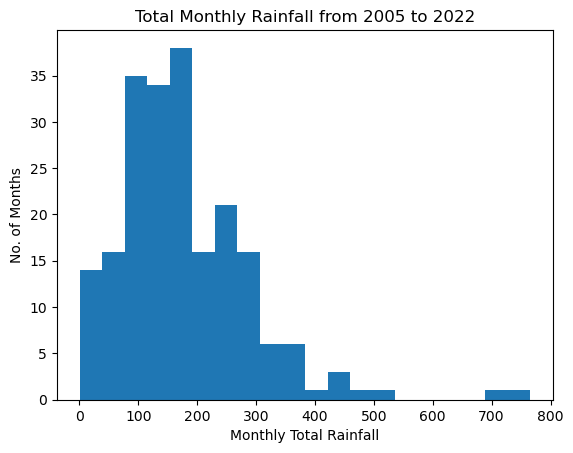

In [28]:
# Histogram of the rainfall data with various bins
plt.hist(df['total_rainfall'], bins=20)
plt.title('Total Monthly Rainfall from 2005 to 2022')
plt.xlabel('Monthly Total Rainfall')
plt.ylabel('No. of Months');

A majority of months recorded rainfall levels between 100 and 300 mm.

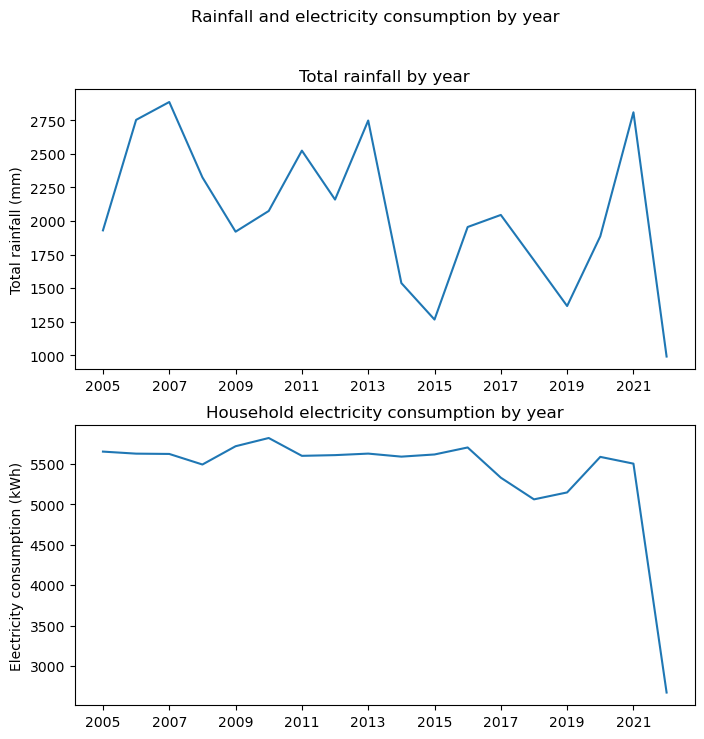

In [29]:
# Line plots of total rainfall and household electricity consumption by year on subplots

# Total rainfall and household electricity consumption by year
groupby_rainfall = df.groupby('year')['total_rainfall'].sum()
groupby_electricity = df.groupby('year')['overall'].sum()

# Figure with two subplots
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(8, 8))

# Total rainfall by year
ax1.plot(groupby_rainfall)

# set the x-axis ticks to display only years and space them out
x_ticks = groupby_rainfall.index[::2]
ax1.set_xticks(x_ticks)

# set the plot title and axis labels
ax1.set_title('Total rainfall by year')
ax1.set_ylabel('Total rainfall (mm)')

# Household electricity consumption by year
ax2.plot(groupby_electricity)

# set the x-axis ticks to display only years and space them out
x_ticks = groupby_electricity.index[::2]
ax2.set_xticks(x_ticks)

# set the plot title and axis labels
ax2.set_title('Household electricity consumption by year')
ax2.set_ylabel('Electricity consumption (kWh)')

# set the overall plot title
fig.suptitle('Rainfall and electricity consumption by year')

# display the plot
plt.show()

Household electricity consumption seems quite consistent across the years as compared to total rainfall and does not appear to be heavily influenced by the amount of rainfall in the corresponding years.

In [30]:
# Compute the correlation matrix
df.corr(numeric_only=True)

,year,overall,central_region,east_region,northeast_region,north_region,west_region,total_rainfall,number_of_rainy_days,air_temperature_means_daily_max,air_temperature_means_daily_min,bright_sunshine_daily_mean_hour,24_hours_mean_relative_humidity_percent
year,1.000000,-0.222914,-0.180372,-0.297971,-0.236857,-0.086038,-0.155703,-0.124645,-0.053244,0.141873,0.336046,0.162893,-0.590485
overall,-0.222914,1.000000,0.978019,0.962263,0.979192,0.960776,0.978852,-0.010602,0.213723,0.077012,0.358771,-0.236157,0.037111
central_region,-0.180372,0.978019,1.000000,0.934990,0.947933,0.935172,0.957996,0.041232,0.251166,0.050944,0.336516,-0.290071,0.044075
east_region,-0.297971,0.962263,0.934990,1.000000,0.937617,0.912074,0.920494,-0.062893,0.161098,0.111361,0.350711,-0.202785,0.066518
northeast_region,-0.236857,0.979192,0.947933,0.937617,1.000000,0.948199,0.969760,-0.022807,0.204254,0.070417,0.340179,-0.230184,0.057018
north_region,-0.086038,0.960776,0.935172,0.912074,0.948199,1.000000,0.964284,-0.048681,0.181837,0.092812,0.383412,-0.193407,-0.053854
west_region,-0.155703,0.978852,0.957996,0.920494,0.969760,0.964284,1.000000,-0.032091,0.190090,0.071363,0.361209,-0.215718,-0.024070
total_rainfall,-0.124645,-0.010602,0.041232,-0.062893,-0.022807,-0.048681,-0.032091,1.000000,0.669216,-0.538031,-0.533937,-0.638065,0.576189
number_of_rainy_days,-0.053244,0.213723,0.251166,0.161098,0.204254,0.181837,0.190090,0.669216,1.000000,-0.403529,-0.365957,-0.729416,0.586159
air_temperature_means_daily_max,0.141873,0.077012,0.050944,0.111361,0.070417,0.092812,0.071363,-0.538031,-0.403529,1.000000,0.623403,0.593202,-0.525245


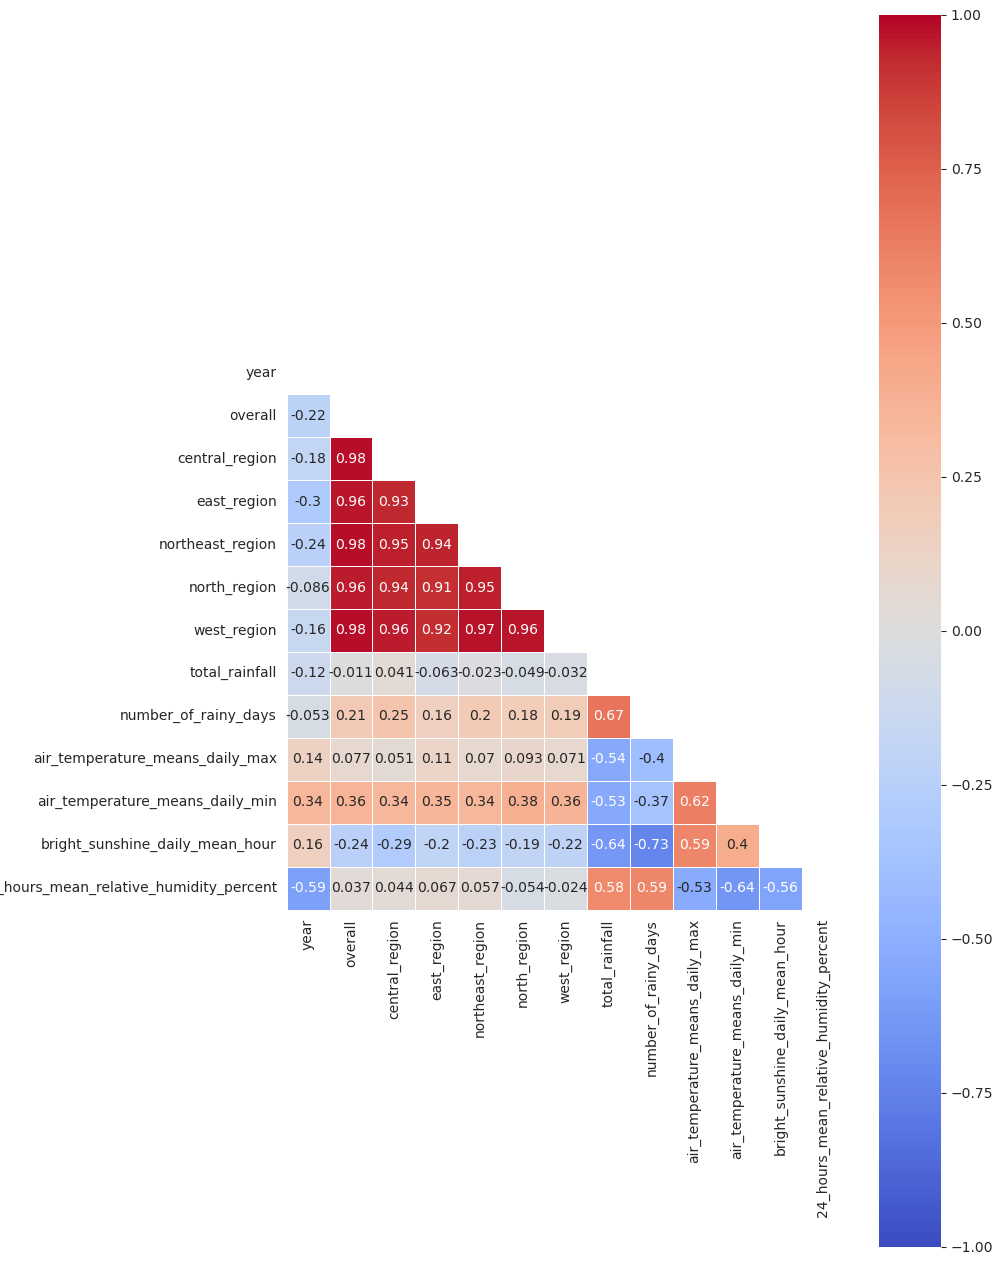

In [ ]:
# Correlation Matrix Heatmap
# Set figure size
plt.figure(figsize = (9,16))

# Get correlation of variables
corr = df.corr(numeric_only=True)

# Generate a mask for the upper triangle to hide unnecesary values
mask = np.zeros_like(corr)
mask[np.triu_indices_from(mask)] = True

# Plot correlation heatmap while masking the upper triangle to be white.
with sns.axes_style("white"):
    sns.heatmap(corr, mask = mask, square = True, annot = True, vmin = -1, vmax = 1, linewidths = .5,cmap='coolwarm');

From the heatmap above, it appears that household electricity consumption are not strongly correlated to rainfall, temperature and humidity. However,the correlation among weather features appears to be in line with common understanding, i.e. number of rainy days are positively correlated to total rainfall in the month and average daily sunshine hours has a positive correlation with maximum daily temperature, etc.

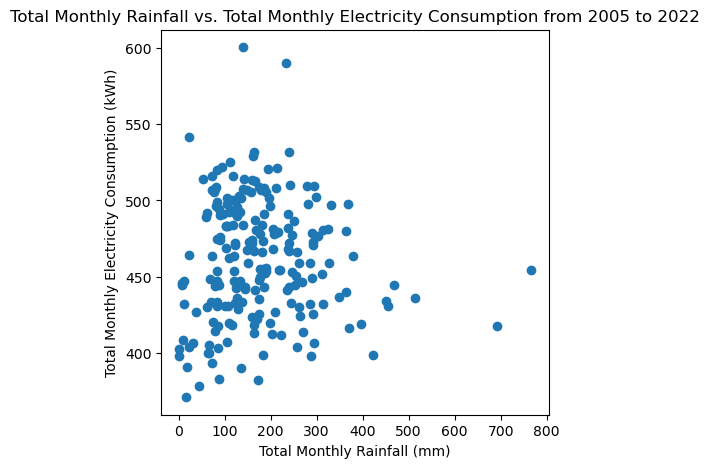

In [32]:
# Scatter plot of total rainfall vs. total electricity consumption
plt.figure(figsize=(5,5))
plt.scatter(df['total_rainfall'], df['overall'])
plt.title('Total Monthly Rainfall vs. Total Monthly Electricity Consumption from 2005 to 2022')
plt.xlabel('Total Monthly Rainfall (mm)')
plt.ylabel('Total Monthly Electricity Consumption (kWh)');

From the scatterplot above, we can see that the correlation between total monthly rainfall and total monthly electricity consumption is not apparent except for a few outliers.

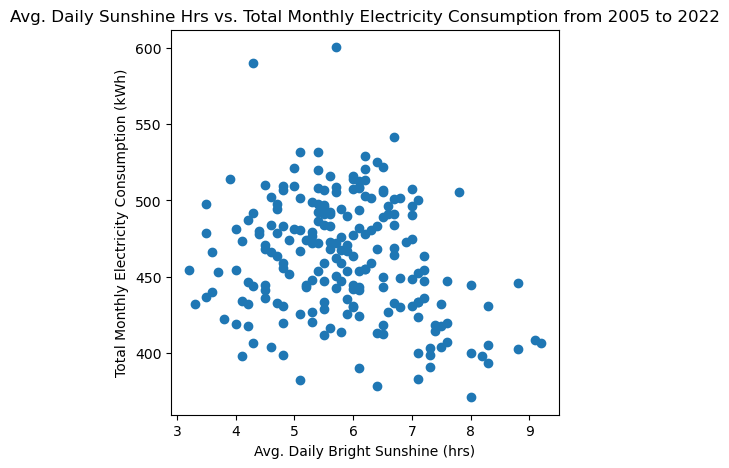

In [33]:
# Scatter plot of Daily Bright Sunshine Hours vs. total electricity consumption
plt.figure(figsize=(5,5))
plt.scatter(df['bright_sunshine_daily_mean_hour'], df['overall'])
plt.title('Avg. Daily Sunshine Hrs vs. Total Monthly Electricity Consumption from 2005 to 2022')
plt.xlabel('Avg. Daily Bright Sunshine (hrs)')
plt.ylabel('Total Monthly Electricity Consumption (kWh)');

The scatterplot above reflects what is shown in the heatmap earlier - that the correlation between average daily bright sunshine hours and total monthly electricity consumption is not significant as well.

## Conclusions and Recommendations

Contrary to what was expected, weather conditions **do not appear to be strongly correlated** to household electricity consumption. There are a couple of possible reasons for this:

* Daytime is typically warmer but many people are unlikely to be at home during this timing especially on weekdays, and hence there is lower demand to switch on the biggest energy guzzler -- air-conditioners.

* Electricity consumption can be complex and will differ based on the types electrical appliances and energy efficiency of the appliances, etc. The amount of electricity consumed by each type of usage differs and not all usages are directly driven by weather patterns. For instance, refrigerator has to be switched on regardless rain or shine. 

As a result, national government agencies may not be able to make meaningful use of these inconclusive findings above. 

One **recommendation for further improvement** is to gather data on commercial electricity consumption for more comprehensive analysis. Electricity consumption of buildings is understandably higher than that of households due to the much larger space area. As reported by [Channel News Asia](https://www.channelnewsasia.com/commentary/air-con-unit-electricity-energy-carbon-emissions-climate-change-1339326), cooling systems consume about 40 to 50 per cent of a building’s energy, which contributes to the urban heat island effect. Hence, the likelihood of finding more significant correlation between commercial electricity consumption and weather conditions will be probably higher. 